# ESTUDO DE CASO: Detecção de Spam | _Classificador Naive Bayes_
___
**LINK DO DATASET ORIGINAL:** https://www.kaggle.com/datasets/abdallahwagih/spam-emails
___



### 1 | Importações:
___

Importando as bibliotecas:

In [1]:
# Manipulação dos dados:
import pandas as pd

# Visualização de dados:
import plotly.express as px
import matplotlib.pyplot as plt

# Machine learning:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

Importando o dataset _spam.csv_:

In [2]:
spam_df = pd.read_csv('../data/spam.csv')
spam_df     # Exibe o dataset no notebook 

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


### 2 | Análise exploratória do dataset
___

Obtendo informações gerais do dataset através do próprio Pandas: 

In [3]:
num_linhas = spam_df.shape[0]
num_colunas = spam_df.shape[1]
num_unicos = spam_df['Message'].nunique()
frequencias = spam_df['Category'].value_counts()


print('ANÁLLISE EXPLORATÓRIA DO SPAM DATASET')
print('-' * 50)
print(f'Número de linhas:  {num_linhas}')
print(f'Número de colunas: {num_colunas}')
print(f'Número de mensagens únicas: {num_unicos}')
print('-' * 50)
print(frequencias)


ANÁLLISE EXPLORATÓRIA DO SPAM DATASET
--------------------------------------------------
Número de linhas:  5572
Número de colunas: 2
Número de mensagens únicas: 5157
--------------------------------------------------
Category
ham     4825
spam     747
Name: count, dtype: int64


Plotando visualmente a distribuição de emails Spam e Não-Spam (chamados de _ham_):

In [4]:
fig = px.pie(
    spam_df,
    names='Category',
    title='Distribuição de emails Ham e Spam:'
)
fig.update_layout(width=600, height=600)
fig.show()

### 3 | Pré-processamento dos dados do dataset
___

É necessário inicialmente converter os rótulos para valores numéricos ('spam' vira 1 e 'ham' vira 0).

In [5]:
mapeamento = {'spam': 1,'ham': 0}                       # 'spam' vira 1 e 'ham' vira 0
spam_df['spam'] = spam_df['Category'].map(mapeamento)   # faz o label encoding em nova coluna
spam_df                                                 # Exibe o dataset no notebook

,Category,Message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,1
5568,ham,Will ü b going to esplanade fr home?,0
5569,ham,"Pity, * was in mood for that. So...any other s...",0
5570,ham,The guy did some bitching but I acted like i'd...,0


### 4 | Divisão dos dados em treino e teste
___


In [6]:
X = spam_df['Message']
y = spam_df['spam']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5 | Vetorização de texto
___

O algoritmo do Naive Bayes do scikit-learn faz cálculos com valores em matrizes numéricas. Isso exige com que a mensagem seja convertida de texto para essas matrizes. Para lidar com isso, é possível usar um de dois vetorizadores de o scikit-learn possui para vetorizar textos:

- _CountVectorizer_: conta a frequência de cada palavra no dataset, sendo ideal para algoritmos que trabalham melhor com valores inteiros;
- _TfidfVectorizer_: calcula o peso TF-IDF, o que pode reduzir o peso de palavras muito comuns no dataset (as _stop words_).

Como a intenção é de utilizar o _MultinomialNB()_, que funciona melhor com valores inteiros, o _CountVectorizer_ será o vetorizador utilizado.

In [7]:
count_vec = CountVectorizer()

In [8]:
X_train_count = count_vec.fit_transform(X_train)
X_test_count = count_vec.transform(X_test)

### 6 | Treinamento e avaliação do Naive Bayes
___


Para esse cenário, é usado o _MultinomialNB_, visto que estamos trabalhando com a contagem discreta das frequências das palavras, e ele foi feito para isso.

In [9]:
modelo_count = MultinomialNB()
modelo_count.fit(X_train_count, y_train)
pred_count = modelo_count.predict(X_test_count)

print(f"Acurácia (CountVectorizer): {accuracy_score(y_test, pred_count) * 100:.2f}%")

Acurácia (CountVectorizer): 99.19%


In [10]:
# Relatório de Classificação Geral (Precision, Recall, F1-Score)
print("-" * 60)
print("RELATÓRIO DE CLASSIFICAÇÃO: MultonomialNB (CountVectorizer)")
print("-" * 60)
print(classification_report(y_test, pred_count, target_names=['Ham (0)', 'Spam (1)']))
print("-" * 60)



------------------------------------------------------------
RELATÓRIO DE CLASSIFICAÇÃO: MultonomialNB (CountVectorizer)
------------------------------------------------------------
              precision    recall  f1-score   support

     Ham (0)       0.99      1.00      1.00       966
    Spam (1)       1.00      0.94      0.97       149

    accuracy                           0.99      1115
   macro avg       1.00      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115

------------------------------------------------------------


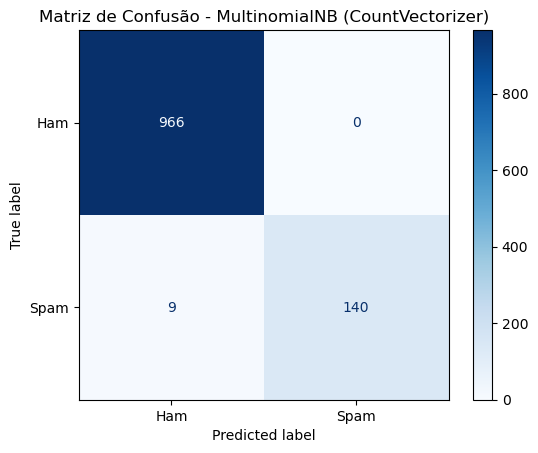

In [11]:
# Geração e plot da matriz de confusão
cm = confusion_matrix(y_test, pred_count)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Spam'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusão - MultinomialNB (CountVectorizer)")
plt.show()

### 7 | Intepretação dos resultados
___

Considerando que o objetivo era detectar o que era spam, não houve falso positivo (já que houve 100% de precisão da classe Spam), mas houveram casos de falso negativos (por conta do _recall_ de 0.94). O que isso siginifica é que nenhuma mensagem importante foi classificada como spam, mas alguns emails de spam foram parar no meio de mensagens 'ham'.

Ainda sim, é importante ressaltar a capacidade do modelo em caracterizar bem o conjunto de spam em um dataset em que eles eram a minoria (cerca de 13.4%).